# A-eye v4 — AI-Generated Video Detector

Frequency-domain + temporal + wavelet features extracted from each video, classified by an MLP.

| Part | Sections |
|---|---|
| Setup | 1 Mount Drive · 2 Imports · 3 Settings |
| A. Features | 4 Temporal sampling · 5 Frequency features · 6 Video feature extractor · 7 Load / extract features |
| B. Training | 8 Source-aware split · 9 Model · 10 Training · 11 Training curves |
| C. Evaluation | 12 Threshold selection · 13 Internal test · 14 Baseline classifiers · 15 Save model |
| D. Interpretability | 16A–16F |
| E. External testing | 17 External test folders · 18 Single uploaded video |

**Feature caches.** All features are cached on Drive. With `REBUILD_FEATURES = False` / `REBUILD_EXTERNAL_FEATURES = False` the saved `.npz` files are loaded directly and no video is decoded.

In [1]:
# ============================================================
# 1. Mount Google Drive
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ============================================================
# 2. Imports
# ============================================================
!pip -q install PyWavelets

import copy, hashlib, json, random
from pathlib import Path

import cv2, pywt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

print('PyTorch:', torch.__version__)

PyTorch: 2.11.0+cpu


In [3]:
# ============================================================
# 3. Settings
# ============================================================
# Drive layout:  Data_1/Real/<source>/...      Data_1/Fake/<generator>/...
#                Data_1/Test/{Real,Fake}/...   Data_1/Test_compress/{Real,Fake}/...
DRIVE_ROOT = Path('/content/drive/MyDrive/Data_1')
FEATURE_DIR, MODEL_DIR, RESULT_DIR = (DRIVE_ROOT / d for d in ('feature_cache_v4', 'models_v4', 'results_v4'))
for d in (FEATURE_DIR, MODEL_DIR, RESULT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Cache controls (False = load the saved feature files, no video decoding) ----
REBUILD_FEATURES = False            # training features (Data_1/Real + Data_1/Fake)
REBUILD_EXTERNAL_FEATURES = False   # external test-folder features
REBUILD_SPLIT = False               # force a new train/val/test split

# ---- Feature extraction (must match the cached features) ----
FEATURE_VERSION = 'v4_freq_temporal_wavelet'
CLASSES = {'real': 0, 'fake': 1}
VIDEO_EXTS = {'.mp4', '.avi', '.mov', '.mkv', '.webm'}
NUM_SEGMENTS, FRAMES_PER_SEGMENT, FRAME_STRIDE = 4, 8, 1
CROP_SIZE, N_CROPS = 256, 5
NUM_BINS = 64
FEATURE_CONFIG = {'feature_version': FEATURE_VERSION, 'num_segments': NUM_SEGMENTS,
                  'frames_per_segment': FRAMES_PER_SEGMENT, 'frame_stride': FRAME_STRIDE,
                  'crop_size': CROP_SIZE, 'n_crops': N_CROPS, 'num_bins': NUM_BINS}

# ---- Training ----
SEED, TEST_SIZE, VAL_SIZE, BATCH_SIZE = 42, 0.15, 0.15, 32
LR, WEIGHT_DECAY, EPOCHS, PATIENCE = 2e-4, 1e-4, 100, 15 #patience= early stoping of epoch
HIDDEN, DROPOUT = (256, 128, 64), 0.30

# ---- Files ----
FEATURES_FILE = FEATURE_DIR / 'features_v4.npz'
SPLIT_FILE = FEATURE_DIR / 'train_val_test_split_v4.npz'
CHECKPOINT = MODEL_DIR / 'mlp_detector_v4.pt'
METRICS_FILE = RESULT_DIR / 'metrics_v4.json'
MISCLASSIFIED_FILE = RESULT_DIR / 'misclassified_test_v4.csv'
TRAINING_CURVE_FILE = RESULT_DIR / 'training_curves_v4.png'
CONFUSION_MATRIX_FILE = RESULT_DIR / 'confusion_matrix_v4.png'
ROC_FILE = RESULT_DIR / 'roc_curve_v4.png'

# Independent test folders (never used for training or threshold selection).
EXTERNAL_SETS = {
    'Test':          {'dir': DRIVE_ROOT / 'Test',
                      'cache': FEATURE_DIR / 'external_test_features_v1.npz',
                      'tag': 'external_folder_test'},
    'Test_compress': {'dir': DRIVE_ROOT / 'Test_compress',
                      'cache': FEATURE_DIR / 'external_test_compress_features_v4.npz',
                      'tag': 'external_folder_compress_test'},
}

# ---- Reproducibility ----
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, '| REBUILD_FEATURES:', REBUILD_FEATURES,
      '| REBUILD_EXTERNAL_FEATURES:', REBUILD_EXTERNAL_FEATURES)

Device: cpu | REBUILD_FEATURES: False | REBUILD_EXTERNAL_FEATURES: False


# Part A — Feature extraction

## 4. Temporal sampling and spatial crops
Each video is split into `NUM_SEGMENTS` evenly spaced temporal segments of `FRAMES_PER_SEGMENT` frames, so the detector does not depend only on the beginning of a clip. Up to `N_CROPS` crops of `CROP_SIZE × CROP_SIZE` (centre + four offset crops) are taken from each segment.

In [4]:
# ============================================================
# 4. Temporal sampling and spatial crops
# ============================================================
def read_temporal_segments(path, num_segments=NUM_SEGMENTS, frames_per_segment=FRAMES_PER_SEGMENT, stride=FRAME_STRIDE):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise IOError(f'Cannot open video: {path}')

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS) or 0.0)
    if total < 3:
        cap.release()
        raise ValueError(f'Video has only {total} frames')

    needed = frames_per_segment * stride
    max_start = max(0, total - needed)
    starts = [0] if num_segments == 1 else np.linspace(0, max_start, num_segments).round().astype(int)

    segments = []
    for start in starts:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(start))
        frames = []
        for k in range(needed):
            ok, frame = cap.read()
            if not ok:
                break
            if k % stride == 0:
                frames.append(frame)
        if len(frames) >= 3:
            segments.append(np.stack(frames))
    cap.release()

    if len(segments) == 0:
        raise ValueError(f'Could not read enough frames from {path}')
    return segments, fps


def resize_if_needed(frames, crop_size=CROP_SIZE):
    h, w = frames.shape[1:3]
    if min(h, w) >= crop_size:
        return frames
    scale = crop_size / min(h, w)
    new_w, new_h = int(np.ceil(w * scale)), int(np.ceil(h * scale))
    return np.stack([cv2.resize(f, (new_w, new_h), interpolation=cv2.INTER_CUBIC) for f in frames])


def crop_boxes(h, w, size=CROP_SIZE):
    cy, cx = (h - size) // 2, (w - size) // 2
    qy, qx = max(0, (h-size)//4), max(0, (w-size)//4)
    raw = [
        (cy, cx),
        (max(0, cy-qy), max(0, cx-qx)),
        (max(0, cy-qy), min(max(0, w-size), cx+qx)),
        (min(max(0, h-size), cy+qy), max(0, cx-qx)),
        (min(max(0, h-size), cy+qy), min(max(0, w-size), cx+qx))
    ]
    return list(dict.fromkeys(raw))  # remove duplicate boxes, keep order


def get_crops(frames):
    frames = resize_if_needed(frames)
    h, w = frames.shape[1:3]
    boxes = crop_boxes(h, w)
    return [frames[:, y0:y0+CROP_SIZE, x0:x0+CROP_SIZE] for y0, x0 in boxes[:N_CROPS]]

## 5. Frequency-domain feature functions
- radial FFT profile (mean, std, temporal drift) and frame-difference FFT
- non-radial 2-D FFT statistics (band energies, centroid, entropy, anisotropy, quadrants)
- high-frequency residual spectrum
- wavelet (db2, 2 levels) detail-band energies
- chroma (Cr / Cb) spectra

In [5]:
# ============================================================
# 5A. FFT helpers
# ============================================================
def make_radial_bins(h, w, num_bins=NUM_BINS):
    yy, xx = np.mgrid[0:h, 0:w]
    yy, xx = yy - h // 2, xx - w // 2
    r = np.sqrt(xx**2 + yy**2)
    r_norm = r / (min(h, w) / 2.0)
    idx = np.floor(r_norm * num_bins).astype(np.int32)
    valid = idx < num_bins
    return idx, valid


def radial_profile(spec, bin_idx, valid, num_bins=NUM_BINS):
    vals, ids = spec[:, valid], bin_idx[valid]
    out = np.zeros((spec.shape[0], num_bins), dtype=np.float32)
    counts = np.bincount(ids, minlength=num_bins)  # identical for every frame, so computed once
    for t in range(spec.shape[0]):
        sums = np.bincount(ids, weights=vals[t], minlength=num_bins)
        out[t] = sums / np.maximum(counts, 1)
    return out


def fft_log_power(frames):
    x = frames.astype(np.float32)
    x = x - x.mean(axis=(1,2), keepdims=True)
    wy, wx = np.hanning(x.shape[1]).astype(np.float32), np.hanning(x.shape[2]).astype(np.float32)
    window = wy[:, None] * wx[None, :]
    x = x * window[None, :, :]
    F = np.fft.fftshift(np.fft.fft2(x, axes=(-2,-1)), axes=(-2,-1))
    power = np.abs(F)**2
    return np.log1p(power).astype(np.float32)


def normalise_profile(p):
    return p - p.mean(axis=1, keepdims=True)


def temporal_drift(a):
    """Mean absolute frame-to-frame change along axis 0 (zeros if only one frame)."""
    return np.abs(a[1:] - a[:-1]).mean(axis=0) if len(a) > 1 else np.zeros(a.shape[1:], dtype=np.float32)


# ============================================================
# 5B. Non-radial 2-D FFT statistics
# ============================================================
def nonradial_fft_features(spec):
    T, H, W = spec.shape
    yy, xx = np.mgrid[0:H, 0:W]
    yy, xx = yy - H//2, xx - W//2
    r = np.sqrt(xx**2 + yy**2)
    rmax = min(H,W)/2

    low = r < 0.20*rmax
    mid = (r >= 0.20*rmax) & (r < 0.50*rmax)
    high = (r >= 0.50*rmax) & (r < 1.00*rmax)
    horizontal = np.abs(yy) <= 0.20*np.maximum(np.abs(xx), 1)
    vertical = np.abs(xx) <= 0.20*np.maximum(np.abs(yy), 1)

    feats = []
    for s in spec:
        total = s.sum() + 1e-8
        low_e, mid_e, high_e = s[low].sum() / total, s[mid].sum() / total, s[high].sum() / total
        centroid = (s * r).sum() / total / rmax
        ent = entropy_from_vector(s.ravel())
        h_e, v_e = s[horizontal].sum(), s[vertical].sum()
        anis = (h_e-v_e) / (h_e+v_e+1e-8)
        q1, q2 = s[:H//2, :W//2].sum() / total, s[:H//2, W//2:].sum() / total
        q3, q4 = s[H//2:, :W//2].sum() / total, s[H//2:, W//2:].sum() / total
        hl_ratio = s[high].mean() / (s[low].mean()+1e-8)
        feats.append([low_e, mid_e, high_e, centroid, ent, anis, q1, q2, q3, q4, hl_ratio])
    return np.asarray(feats, dtype=np.float32)

def entropy_from_vector(v):
    v = np.maximum(v, 1e-12)
    p = v / v.sum()
    return float(-(p * np.log(p + 1e-12)).sum())


# ============================================================
# 5C. High-frequency residual features
# ============================================================
def residual_features(gray):
    residual = np.asarray([f - cv2.GaussianBlur(f, (0,0), sigmaX=1.0) for f in gray], dtype=np.float32)
    spec = fft_log_power(residual)
    bin_idx, valid = make_radial_bins(gray.shape[1], gray.shape[2])
    prof = radial_profile(spec, bin_idx, valid)
    prof_n = normalise_profile(prof)

    rms = np.sqrt(np.mean(residual**2, axis=(1,2)))
    std = residual.std(axis=(1,2))
    abs_mean = np.abs(residual).mean(axis=(1,2))
    radial_mean, radial_std = prof_n.mean(axis=0), prof_n.std(axis=0)
    drift = temporal_drift(prof_n)

    scalar = np.array([rms.mean(), rms.std(), std.mean(), std.std(), abs_mean.mean(), abs_mean.std()], dtype=np.float32)
    return np.concatenate([radial_mean, radial_std, drift, scalar]).astype(np.float32)


# ============================================================
# 5D. Wavelet features
# ============================================================
def wavelet_features(gray):
    feats = []
    for f in gray:
        coeffs = pywt.wavedec2(f, 'db2', level=2)
        bands = [*coeffs[1], *coeffs[2]]  # (H, V, D) detail bands at both levels
        energies = [np.mean(b**2) for b in bands]
        feats.append(energies)
    feats = np.asarray(feats, dtype=np.float32)

    mean, std = feats.mean(axis=0), feats.std(axis=0)
    drift = temporal_drift(feats)
    return np.concatenate([mean, std, drift]).astype(np.float32)


# ============================================================
# 5E. Chroma frequency features
# ============================================================
def chroma_features(crop_bgr):
    ycc = np.stack([cv2.cvtColor(np.ascontiguousarray(f), cv2.COLOR_BGR2YCrCb) for f in crop_bgr]).astype(np.float32) / 255.0
    out = []
    for ch in [1, 2]:  # Cr, Cb
        channel = ycc[..., ch]
        spec = fft_log_power(channel)
        bin_idx, valid = make_radial_bins(channel.shape[1], channel.shape[2])
        prof = radial_profile(spec, bin_idx, valid)
        prof_n = normalise_profile(prof)
        out += [prof_n.mean(axis=0), prof_n.std(axis=0)]
    return np.concatenate(out).astype(np.float32)

## 6. Per-crop and per-video feature extractor
Per crop → features above; crops are aggregated by mean and std, then segments are aggregated by mean and std across the video (3068-D vector).

In [6]:
# ============================================================
# 6A. Features from one temporal segment/crop
# ============================================================
def segment_crop_features(crop_bgr):
    gray = np.stack([cv2.cvtColor(np.ascontiguousarray(f), cv2.COLOR_BGR2GRAY) for f in crop_bgr]).astype(np.float32) / 255.0
    H, W = gray.shape[1:]
    bin_idx, valid = make_radial_bins(H, W)

    # Main grayscale FFT
    spec = fft_log_power(gray)
    prof = radial_profile(spec, bin_idx, valid)
    prof_n = normalise_profile(prof)
    mean_prof, std_prof, drift_prof = prof_n.mean(axis=0), prof_n.std(axis=0), temporal_drift(prof_n)

    # FFT of frame differences
    frame_diff = gray[1:] - gray[:-1]
    if len(frame_diff) > 0:
        diff_spec = fft_log_power(frame_diff)
        diff_prof = radial_profile(diff_spec, bin_idx, valid).mean(axis=0)
        diff_prof = diff_prof - diff_prof.mean()
    else:
        diff_prof = np.zeros(NUM_BINS, dtype=np.float32)
    radial_features = np.concatenate([mean_prof, std_prof, drift_prof, diff_prof])

    # Non-radial 2-D FFT
    nr = nonradial_fft_features(spec)
    nr_mean, nr_std, nr_drift = nr.mean(axis=0), nr.std(axis=0), temporal_drift(nr)
    nonradial_features = np.concatenate([nr_mean, nr_std, nr_drift])

    # Residual / Wavelet / Chroma
    residual = residual_features(gray)
    wave = wavelet_features(gray)
    chroma = chroma_features(crop_bgr)

    # Temporal scalars
    hf = prof[:, NUM_BINS//2:].mean(axis=1) - prof[:, :NUM_BINS//2].mean(axis=1)
    if len(spec) > 1:
        spec_change = np.abs(spec[1:] - spec[:-1])
        spec_scalars = [np.mean(spec_change), np.std(spec_change), np.max(spec_change)]
    else:
        spec_scalars = [0.0, 0.0, 0.0]
    hf_drift = temporal_drift(hf)
    temporal_scalars = np.array([*spec_scalars, hf.mean(), hf.std(), hf_drift], dtype=np.float32)

    return np.concatenate([radial_features, nonradial_features, residual, wave, chroma, temporal_scalars]).astype(np.float32)


# ============================================================
# 6B. Complete video feature extractor
# ============================================================
def extract_video_features_v4(path):
    segments, _ = read_temporal_segments(path)
    segment_features = []
    for seg in segments:
        crops = get_crops(seg)
        crop_features = np.stack([segment_crop_features(crop) for crop in crops])
        # IMPORTANT: retain both mean and spatial variability.
        crop_mean, crop_std = crop_features.mean(axis=0), crop_features.std(axis=0)
        segment_features.append(np.concatenate([crop_mean, crop_std]))
    segment_features = np.stack(segment_features)

    # Temporal aggregation across the whole video.
    video_mean, video_std = segment_features.mean(axis=0), segment_features.std(axis=0)
    return np.concatenate([video_mean, video_std]).astype(np.float32)

## 7. Load (or extract) the training features
`REBUILD_FEATURES = False` → the saved `features_v4.npz` is loaded directly.
`REBUILD_FEATURES = True` → every video under `Data_1/Real` and `Data_1/Fake` is processed and the cache is overwritten.
The same `load_or_extract_features` function is reused for the external test folders in Section 17.

In [7]:
# ============================================================
# 7. Load (or extract) persistent features
# ============================================================
def find_child_dir(parent, name):
    """Direct child directory matched case-insensitively (Real/real)."""
    return next((p for p in parent.iterdir() if p.is_dir() and p.name.lower() == name), None)


def list_videos(root):
    """(path, label) pairs from root/Real and root/Fake, searched recursively."""
    items = []
    for cls_name, label in CLASSES.items():
        cls_dir = find_child_dir(root, cls_name)
        if cls_dir is None:
            raise FileNotFoundError(f"Missing '{cls_name}' folder under {root}")
        vids = sorted(p for p in cls_dir.rglob('*') if p.is_file() and p.suffix.lower() in VIDEO_EXTS)
        print(f"{cls_name:>5}: {len(vids)} videos in {cls_dir}")
        items += [(p, label) for p in vids]
    if not items:
        raise RuntimeError(f"No supported videos found under {root}")
    return items


def load_or_extract_features(cache_file, video_root, rebuild, desc):
    """Load cached (X, y, paths); extract from the videos and overwrite the cache only if rebuild=True."""
    if not rebuild:
        if not cache_file.exists():
            raise FileNotFoundError(f"Feature cache not found: {cache_file}. "
                                    "Set the corresponding REBUILD flag to True to extract it.")
        d = np.load(cache_file, allow_pickle=False)
        print('Loaded cached features:', cache_file)
        return d['X'].astype(np.float32), d['y'].astype(np.int64), d['paths'].astype(str)

    feats, labels, vid_paths, failed = [], [], [], []
    for path, label in tqdm(list_videos(video_root), desc=desc):
        try:
            feat = extract_video_features_v4(path)
            if not np.all(np.isfinite(feat)):
                raise ValueError('Non-finite feature values')
            feats.append(feat)
            labels.append(label)
            vid_paths.append(str(path))
        except Exception as e:
            failed.append({'path': str(path), 'error': str(e)})
    if not feats:
        raise RuntimeError('No videos were processed successfully.')

    X_, y_, paths_ = np.stack(feats).astype(np.float32), np.asarray(labels, np.int64), np.asarray(vid_paths, str)
    np.savez_compressed(cache_file, X=X_, y=y_, paths=paths_)
    with open(cache_file.with_name(cache_file.stem + '_metadata.json'), 'w') as f:
        json.dump({'feature_config': FEATURE_CONFIG, 'num_successful': len(X_), 'num_failed': len(failed),
                   'failed': failed, 'created_at': pd.Timestamp.now().isoformat()}, f, indent=2)
    print(f"Saved {cache_file} | successful: {len(X_)} | failed: {len(failed)}")
    for item in failed:
        print('  FAILED:', item['path'], '|', item['error'])
    return X_, y_, paths_


X, y, paths = load_or_extract_features(FEATURES_FILE, DRIVE_ROOT, REBUILD_FEATURES, 'Training features')
assert np.all(np.isfinite(X)), 'Feature matrix contains non-finite values'
print(f"Feature matrix: {X.shape} | real: {int((y == 0).sum())} | fake: {int((y == 1).sum())}")

Loaded cached features: /content/drive/MyDrive/Data_1/feature_cache_v4/features_v4.npz
Feature matrix: (2380, 3068) | real: 1187 | fake: 1193


# Part B — Training

## 8. Source-aware train / validation / internal-test split
Videos are split *inside* each source/generator folder, so every source contributes to all three splits. The saved split is reused as long as the list of cached video paths is unchanged. Normalisation statistics come from the training split only.

In [8]:
# ============================================================
# 8. Source-aware split + training-set normalisation
# ============================================================
def source_group(path):
    """'Real/net', 'Fake/sora', ... (class folder / first sub-folder)."""
    try:
        rel = Path(path).relative_to(DRIVE_ROOT).parts
        return f"{rel[0]}/{rel[1]}" if len(rel) > 2 else f"{rel[0]}/(root)"
    except ValueError:
        return Path(path).parent.name


def split_indices_by_source(paths, seed=SEED):
    rng = np.random.default_rng(seed)
    groups = {}
    for i, p in enumerate(paths):
        groups.setdefault(source_group(p), []).append(i)

    train_ids, val_ids, test_ids = [], [], []
    for name in sorted(groups):
        ids = np.asarray(groups[name], dtype=int)
        ids = ids[rng.permutation(len(ids))]
        n = len(ids)
        if n >= 3:
            n_test, n_val = max(1, round(n * TEST_SIZE)), max(1, round(n * VAL_SIZE))
            while n_test + n_val >= n:          # leave at least one training video
                if n_test >= n_val and n_test > 1:
                    n_test -= 1
                elif n_val > 1:
                    n_val -= 1
                else:
                    break
            test_ids += ids[:n_test].tolist()
            val_ids += ids[n_test:n_test + n_val].tolist()
            train_ids += ids[n_test + n_val:].tolist()
        elif n == 2:                            # cannot cover all three splits
            train_ids.append(ids[0])
            test_ids.append(ids[1])
        else:
            train_ids += ids.tolist()
    return tuple(np.asarray(sorted(s), dtype=int) for s in (train_ids, val_ids, test_ids))


paths_hash = hashlib.sha256(json.dumps([str(p) for p in paths]).encode('utf-8')).hexdigest()
split_loaded = False
if not REBUILD_SPLIT and SPLIT_FILE.exists():
    s = np.load(SPLIT_FILE, allow_pickle=False)
    if 'paths_hash' in s.files and str(s['paths_hash'].item()) == paths_hash:
        train_idx, val_idx, test_idx = (s[k].astype(int) for k in ('train_idx', 'val_idx', 'test_idx'))
        split_loaded = True

if split_loaded:
    print('Loaded saved split:', SPLIT_FILE)
else:
    train_idx, val_idx, test_idx = split_indices_by_source(paths, SEED)
    np.savez_compressed(SPLIT_FILE, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx,
                        paths_hash=np.asarray(paths_hash), seed=np.asarray(SEED))
    print('Created and saved a new split:', SPLIT_FILE)

split_of = np.empty(len(paths), dtype=object)
for name, ids in (('train', train_idx), ('val', val_idx), ('test', test_idx)):
    split_of[ids] = name
groups = [source_group(p) for p in paths]
print('\nVideos per source and split:')
display(pd.crosstab(pd.Series(groups, name='source'), pd.Series(split_of, name='split'),
                    margins=True)[['train', 'val', 'test', 'All']])
print('Class balance per split:')
display(pd.crosstab(pd.Series(split_of, name='split'),
                    pd.Series(np.where(y == 1, 'fake', 'real'), name='class')).loc[['train', 'val', 'test']])

# Training-set-only normalisation
mean = X[train_idx].mean(axis=0)
std = X[train_idx].std(axis=0)
std[std < 1e-6] = 1.0
Xn = (X - mean) / std

Loaded saved split: /content/drive/MyDrive/Data_1/feature_cache_v4/train_val_test_split_v4.npz

Videos per source and split:


split,train,val,test,All
source,,,,
Fake/crafter,71,15,15,101
Fake/gen2,87,19,19,125
Fake/hotshot,69,15,15,99
Fake/lavie,78,17,17,112
Fake/modelscope,78,16,16,110
Fake/moonvalley,118,25,25,168
Fake/morph,85,18,18,121
Fake/reduced_videos,62,14,14,90
Fake/self,45,9,9,63


Class balance per split:


class,fake,real
split,,
train,837,833
val,178,177
test,178,177


## 9. Model — frequency-feature MLP

In [9]:
# ============================================================
# 9. Frequency-feature MLP
# ============================================================
class FreqMLP(nn.Module):
    def __init__(self, in_dim, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 2))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


model = FreqMLP(X.shape[1]).to(device)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))

FreqMLP(
  (net): Sequential(
    (0): Linear(in_features=3068, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 827842


## 10. Training
Class-weighted cross-entropy, AdamW, `ReduceLROnPlateau`, and early stopping on validation loss (best weights restored).

In [10]:
# ============================================================
# 10. Data loaders + MLP training
# ============================================================
def make_loader(ids, shuffle=False):
    ds = TensorDataset(torch.from_numpy(Xn[ids]).float(), torch.from_numpy(y[ids]).long())
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle)


train_dl, val_dl = make_loader(train_idx, shuffle=True), make_loader(val_idx)

class_counts = np.bincount(y[train_idx], minlength=2)
class_weights = len(train_idx) / (2.0 * class_counts)
print('Class counts:', class_counts, '| class weights:', class_weights.round(4))

loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device))
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)


def run_epoch(loader, training=False):
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        with torch.set_grad_enabled(training):
            logits = model(xb)
            loss = loss_fn(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        total += len(yb)
    return total_loss / total, correct / total


history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss, best_state, best_epoch, patience_counter = np.inf, None, 0, 0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_dl, training=True)
    val_loss, val_acc = run_epoch(val_dl)
    scheduler.step(val_loss)
    for key, val in zip(history, (train_loss, val_loss, train_acc, val_acc)):
        history[key].append(val)

    if val_loss < best_val_loss - 1e-5:
        best_val_loss, best_state, best_epoch, patience_counter = val_loss, copy.deepcopy(model.state_dict()), epoch, 0
    else:
        patience_counter += 1

    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch {epoch:3d} | train loss {train_loss:.4f} acc {train_acc:.3f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.3f} | lr {optimizer.param_groups[0]['lr']:.2e}")
    if patience_counter >= PATIENCE:
        print('Early stopping at epoch', epoch)
        break

model.load_state_dict(best_state)
print(f"\nBest epoch: {best_epoch} | best validation loss: {best_val_loss:.4f}")

Class counts: [833 837] | class weights: [1.0024 0.9976]
Epoch   1 | train loss 0.4308 acc 0.834 | val loss 0.3254 acc 0.862 | lr 2.00e-04
Epoch   5 | train loss 0.2026 acc 0.933 | val loss 0.1867 acc 0.932 | lr 2.00e-04
Epoch  10 | train loss 0.1314 acc 0.958 | val loss 0.1568 acc 0.944 | lr 2.00e-04
Epoch  15 | train loss 0.1041 acc 0.963 | val loss 0.1464 acc 0.941 | lr 2.00e-04
Epoch  20 | train loss 0.1049 acc 0.962 | val loss 0.1755 acc 0.941 | lr 2.00e-04
Epoch  25 | train loss 0.0591 acc 0.979 | val loss 0.1342 acc 0.952 | lr 1.00e-04
Epoch  30 | train loss 0.0592 acc 0.982 | val loss 0.1337 acc 0.952 | lr 1.00e-04
Epoch  35 | train loss 0.0414 acc 0.990 | val loss 0.1281 acc 0.958 | lr 1.00e-04
Epoch  40 | train loss 0.0247 acc 0.996 | val loss 0.1403 acc 0.961 | lr 1.00e-04
Epoch  45 | train loss 0.0248 acc 0.995 | val loss 0.1351 acc 0.961 | lr 5.00e-05
Epoch  50 | train loss 0.0292 acc 0.991 | val loss 0.1360 acc 0.955 | lr 2.50e-05
Early stopping at epoch 52

Best epoch: 3

## 11. Training curves

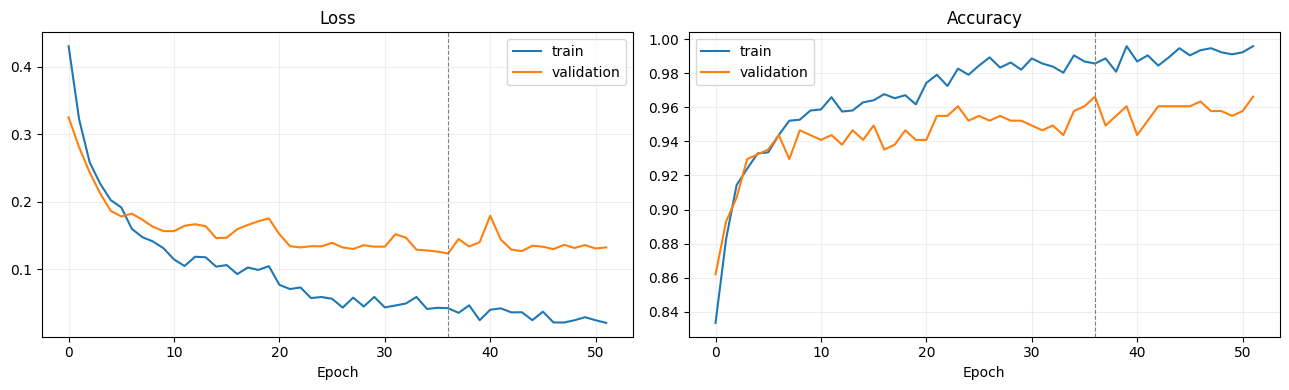

Saved: /content/drive/MyDrive/Data_1/results_v4/training_curves_v4.png


In [11]:
# ============================================================
# 11. Training curves
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, key, title in [(ax[0], 'loss', 'Loss'), (ax[1], 'acc', 'Accuracy')]:
    a.plot(history[f'train_{key}'], label='train')
    a.plot(history[f'val_{key}'], label='validation')
    a.axvline(best_epoch - 1, ls='--', c='gray', lw=0.8)
    a.set(title=title, xlabel='Epoch')
    a.legend()
    a.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(TRAINING_CURVE_FILE, dpi=150, bbox_inches='tight')
plt.show()
print('Saved:', TRAINING_CURVE_FILE)

# Part C — Evaluation

## 12. Decision-threshold selection (validation set only)
The threshold on P(fake) is chosen to maximise validation F1; the internal test set and external folders are never used for this choice.

Validation-selected threshold: 0.5
accuracy     0.9662
precision    0.9826
recall       0.9494
f1           0.9657


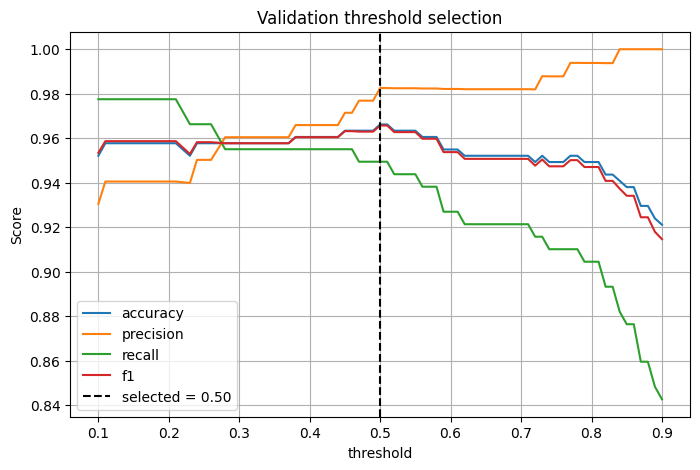

In [12]:
# ============================================================
# 12. Evaluation helpers + validation threshold selection
# ============================================================
def predict_proba(net, X_norm):
    """P(fake) for already-normalised features."""
    net.eval()
    dev = next(net.parameters()).device
    with torch.no_grad():
        return torch.softmax(net(torch.from_numpy(X_norm).float().to(dev)), dim=1)[:, 1].cpu().numpy()


def compute_metrics(y_true, prob, threshold, with_auc=True):
    pred = (prob >= threshold).astype(int)
    m = {'accuracy': accuracy_score(y_true, pred),
         'precision': precision_score(y_true, pred, zero_division=0),
         'recall': recall_score(y_true, pred, zero_division=0),
         'f1': f1_score(y_true, pred, zero_division=0)}
    if with_auc:
        m['roc_auc'] = roc_auc_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan
    return m


def report(title, y_true, prob, threshold, cm_file):
    """Print metrics + classification report, save the confusion matrix, return the metrics."""
    pred = (prob >= threshold).astype(int)
    m = compute_metrics(y_true, prob, threshold)
    print('=' * 60 + f'\n{title}  (n = {len(y_true)}, threshold = {threshold:.2f})\n' + '=' * 60)
    for k, v in m.items():
        print(f"{k:<10}: {v:.4f}")
    print('\n' + classification_report(y_true, pred, labels=[0, 1], target_names=['real', 'fake'],
                                       digits=4, zero_division=0))
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['real', 'fake']).plot(cmap='Blues', values_format='d')
    plt.title(f'{title} (threshold = {threshold:.2f})')
    plt.savefig(cm_file, dpi=150, bbox_inches='tight')
    plt.show()
    print('Saved:', cm_file)
    return {**m, 'confusion_matrix': cm.tolist()}


y_val, p_val = y[val_idx], predict_proba(model, Xn[val_idx])
thresholds = np.round(np.arange(0.10, 0.91, 0.01), 2)
thr_df = pd.DataFrame([{'threshold': t, **compute_metrics(y_val, p_val, t, with_auc=False)} for t in thresholds])
best_row = thr_df.loc[thr_df['f1'].idxmax()]
BEST_THRESHOLD = float(best_row['threshold'])
print('Validation-selected threshold:', BEST_THRESHOLD)
print(best_row.drop('threshold').round(4).to_string())

ax = thr_df.plot(x='threshold', y=['accuracy', 'precision', 'recall', 'f1'], figsize=(8, 5), grid=True)
ax.axvline(BEST_THRESHOLD, ls='--', c='k', label=f'selected = {BEST_THRESHOLD:.2f}')
ax.set(ylabel='Score', title='Validation threshold selection')
ax.legend()
plt.show()

## 13. Internal held-out test set

Internal test set  (n = 355, threshold = 0.50)
accuracy  : 0.9549
precision : 0.9655
recall    : 0.9438
f1        : 0.9545
roc_auc   : 0.9911

              precision    recall  f1-score   support

        real     0.9448    0.9661    0.9553       177
        fake     0.9655    0.9438    0.9545       178

    accuracy                         0.9549       355
   macro avg     0.9551    0.9550    0.9549       355
weighted avg     0.9552    0.9549    0.9549       355



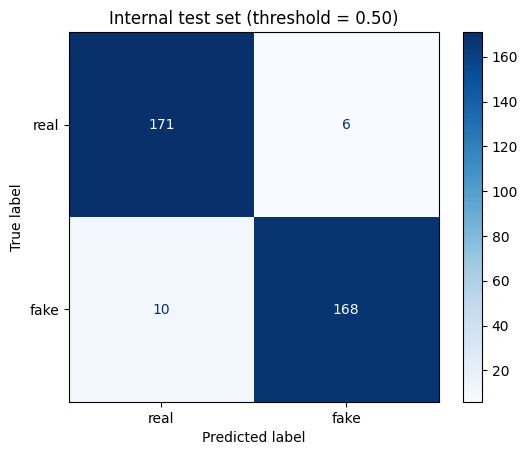

Saved: /content/drive/MyDrive/Data_1/results_v4/confusion_matrix_v4.png


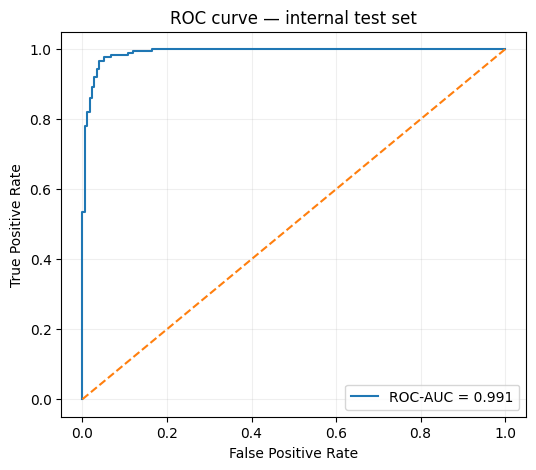

Saved: /content/drive/MyDrive/Data_1/results_v4/roc_curve_v4.png

Misclassified: 16 / 355 | saved: /content/drive/MyDrive/Data_1/results_v4/misclassified_test_v4.csv


,path,true_label,predicted_label,probability_fake,error_type
0,/content/drive/MyDrive/Data_1/Real/Compress/Co...,real,fake,0.972111,false_positive
1,/content/drive/MyDrive/Data_1/Real/net/Copy of...,real,fake,0.994252,false_positive
2,/content/drive/MyDrive/Data_1/Real/net/Copy of...,real,fake,0.962586,false_positive
3,/content/drive/MyDrive/Data_1/Real/net/Copy of...,real,fake,0.767624,false_positive
4,/content/drive/MyDrive/Data_1/Real/net/R8FDJgV...,real,fake,0.933075,false_positive
5,/content/drive/MyDrive/Data_1/Real/net/sm0OYD0...,real,fake,0.878575,false_positive
6,/content/drive/MyDrive/Data_1/Fake/lavie/lavie...,fake,real,0.223516,false_negative
7,/content/drive/MyDrive/Data_1/Fake/lavie/lavie...,fake,real,0.119782,false_negative
8,/content/drive/MyDrive/Data_1/Fake/reduced_vid...,fake,real,0.338850,false_negative
9,/content/drive/MyDrive/Data_1/Fake/self/output...,fake,real,0.100373,false_negative


In [13]:
# ============================================================
# 13. Internal test evaluation: metrics, confusion matrix, ROC, misclassified videos
# ============================================================
y_test, p_test = y[test_idx], predict_proba(model, Xn[test_idx])
pred_test = (p_test >= BEST_THRESHOLD).astype(int)
test_metrics = report('Internal test set', y_test, p_test, BEST_THRESHOLD, CONFUSION_MATRIX_FILE)

# ROC curve
fpr, tpr, _ = roc_curve(y_test, p_test)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {test_metrics['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve — internal test set')
plt.legend()
plt.grid(alpha=0.2)
plt.savefig(ROC_FILE, dpi=150, bbox_inches='tight')
plt.show()
print('Saved:', ROC_FILE)

# Misclassified test videos
wrong = np.where(pred_test != y_test)[0]
wrong_df = pd.DataFrame({
    'path': paths[test_idx[wrong]],
    'true_label': np.where(y_test[wrong] == 1, 'fake', 'real'),
    'predicted_label': np.where(pred_test[wrong] == 1, 'fake', 'real'),
    'probability_fake': p_test[wrong],
    'error_type': np.where(y_test[wrong] == 0, 'false_positive', 'false_negative'),
})
wrong_df.to_csv(MISCLASSIFIED_FILE, index=False)
print(f"\nMisclassified: {len(wrong_df)} / {len(test_idx)} | saved: {MISCLASSIFIED_FILE}")
display(wrong_df)

## 15. Save the trained model

In [14]:
# ============================================================
# 15. Save model checkpoint + metrics
# ============================================================
torch.save({
    'state_dict': model.state_dict(), 'in_dim': int(X.shape[1]),
    'mean': torch.from_numpy(mean.astype(np.float32)), 'std': torch.from_numpy(std.astype(np.float32)),
    'threshold': BEST_THRESHOLD, 'hidden': HIDDEN, 'dropout': DROPOUT, 'seed': SEED,
    **FEATURE_CONFIG,
}, CHECKPOINT)

with open(METRICS_FILE, 'w') as f:
    json.dump({**{k: (v if k == 'confusion_matrix' else float(v)) for k, v in test_metrics.items()},
               'threshold': BEST_THRESHOLD, 'best_epoch': int(best_epoch),
               'num_total': int(len(y)), 'num_train': int(len(train_idx)), 'num_val': int(len(val_idx)),
               'num_test': int(len(test_idx)), 'feature_dimension': int(X.shape[1])}, f, indent=2)

print('Model saved  :', CHECKPOINT)
print('Metrics saved:', METRICS_FILE)

Model saved  : /content/drive/MyDrive/Data_1/models_v4/mlp_detector_v4.pt
Metrics saved: /content/drive/MyDrive/Data_1/results_v4/metrics_v4.json


# Part D — Interpretability

Read-only analysis of the trained model: nothing used for training or evaluation is modified. Six figures are saved to `results_v4/interpretability_v4_top6/`.

| Figure | Content |
|---|---|
| fig1 | Class-average frequency signatures + per-bin effect size |
| fig2 | Integrated-Gradients attribution per feature block / family |
| fig3 | Frequency-resolved attribution |
| fig4 | Block permutation importance |
| fig5 | Raw-video 2-D spectra (real vs fake) |
| fig6 | Per-video top feature contributions |

In [15]:
# ============================================================
# 16A. Interpretability setup — feature-index map + output folder
# ============================================================
INTERP_DIR = RESULT_DIR / 'interpretability_v4_top6'
INTERP_DIR.mkdir(parents=True, exist_ok=True)

N_VIZ_VIDEOS_PER_CLASS = 12   # raw test videos re-read per class for the 2-D spectrum figures
IG_STEPS = 64                 # Integrated-Gradients integration steps
PERM_REPEATS = 5              # repeats for block permutation importance
viz_rng = np.random.RandomState(SEED)

CLASS_COLORS = {0: 'tab:blue', 1: 'tab:red'}
CLASS_NAMES = {0: 'real', 1: 'fake'}
FREQ_AXIS = (np.arange(NUM_BINS) + 0.5) / NUM_BINS   # radial frequency as a fraction of Nyquist


def save_and_show(fig, name):
    out = INTERP_DIR / name
    fig.savefig(out, dpi=160, bbox_inches='tight')
    plt.show()
    print("Saved:", out)
    return out


def build_feature_layout(num_bins=NUM_BINS):
    # Names of the per-crop features in EXACTLY the order produced by segment_crop_features().
    B = num_bins
    nr_names = ['low_E', 'mid_E', 'high_E', 'centroid', 'entropy', 'anisotropy',
                'q1', 'q2', 'q3', 'q4', 'HF/LF']
    wv_names = [f'L{lvl}_{o}' for lvl in (2, 1) for o in ('H', 'V', 'D')]   # wavedec2 order: coarse → fine
    res_scalar = ['rms_mean', 'rms_std', 'std_mean', 'std_std', 'absmean_mean', 'absmean_std']
    tmp_scalar = ['spec_change_mean', 'spec_change_std', 'spec_change_max',
                  'HF-LF_mean', 'HF-LF_std', 'HF-LF_drift']

    base = []   # (block, family, item, bin)
    def add_bins(block, family):
        base.extend((block, family, f'bin{b}', b) for b in range(B))
    def add_items(block, family, names):
        base.extend((block, family, n, -1) for n in names)

    # radial_features
    add_bins('FFT radial mean', 'Spatial spectrum')
    add_bins('FFT radial std', 'Spatial spectrum')
    add_bins('FFT temporal drift', 'Temporal frequency change')
    add_bins('Frame-diff FFT', 'Temporal frequency change')
    # nonradial_features
    add_items('2-D FFT stats mean', 'Spatial spectrum', nr_names)
    add_items('2-D FFT stats std', 'Spatial spectrum', nr_names)
    add_items('2-D FFT stats drift', 'Temporal frequency change', nr_names)
    # residual_features
    add_bins('Residual radial mean', 'HF residual')
    add_bins('Residual radial std', 'HF residual')
    add_bins('Residual temporal drift', 'Temporal frequency change')
    add_items('Residual scalars', 'HF residual', res_scalar)
    # wavelet_features
    add_items('Wavelet energy mean', 'Wavelet', wv_names)
    add_items('Wavelet energy std', 'Wavelet', wv_names)
    add_items('Wavelet temporal drift', 'Temporal frequency change', wv_names)
    # chroma_features
    add_bins('Chroma Cr radial mean', 'Chroma spectrum')
    add_bins('Chroma Cr radial std', 'Chroma spectrum')
    add_bins('Chroma Cb radial mean', 'Chroma spectrum')
    add_bins('Chroma Cb radial std', 'Chroma spectrum')
    # temporal scalars
    add_items('Temporal scalars', 'Temporal frequency change', tmp_scalar)

    rows_ = []
    for video_agg in ('video_mean', 'video_std'):        # extract_video_features_v4: [video_mean, video_std]
        for crop_agg in ('crop_mean', 'crop_std'):       # each = [crop_mean, crop_std]
            for block, family, item, b in base:
                rows_.append({'block': block, 'family': family, 'item': item, 'bin': b,
                              'crop_agg': crop_agg, 'video_agg': video_agg})
    info = pd.DataFrame(rows_)
    info['index'] = np.arange(len(info))
    info['label'] = (info['block'] + ' [' + info['item'] + '] ' + info['crop_agg'].str.replace('crop_', 'c-')
                     + '/' + info['video_agg'].str.replace('video_', 'v-'))
    return info


FEATURE_INFO = build_feature_layout()
assert len(FEATURE_INFO) == X.shape[1], f"Layout {len(FEATURE_INFO)} != feature dim {X.shape[1]}"

BLOCKS = list(dict.fromkeys(FEATURE_INFO['block']))
FAMILIES = list(dict.fromkeys(FEATURE_INFO['family']))
FAMILY_COLORS = dict(zip(FAMILIES, plt.cm.tab10.colors))
BLOCK_TO_FAMILY = dict(zip(FEATURE_INFO['block'], FEATURE_INFO['family']))


def block_bin_indices(block, crop_agg='crop_mean', video_agg='video_mean'):
    # Column indices of a binned block (sorted by frequency bin) for one aggregation copy.
    q = FEATURE_INFO[(FEATURE_INFO.block == block) & (FEATURE_INFO.crop_agg == crop_agg)
                     & (FEATURE_INFO.video_agg == video_agg)].sort_values('bin')
    return q['index'].to_numpy()


def block_indices(block):
    return FEATURE_INFO.loc[FEATURE_INFO.block == block, 'index'].to_numpy()


def cohens_d(a, b):
    # Effect size (fake − real) / pooled std, per column.
    va, vb = a.var(axis=0, ddof=1), b.var(axis=0, ddof=1)
    pooled = np.sqrt(((len(a) - 1) * va + (len(b) - 1) * vb) / max(len(a) + len(b) - 2, 1))
    return (b.mean(axis=0) - a.mean(axis=0)) / np.maximum(pooled, 1e-12)


print("Output folder:", INTERP_DIR)
print("Feature layout verified:", len(FEATURE_INFO), "features,", len(BLOCKS), "blocks,", len(FAMILIES), "families")
display(FEATURE_INFO.groupby(['family', 'block'], sort=False).size().rename('n_features').to_frame())

Output folder: /content/drive/MyDrive/Data_1/results_v4/interpretability_v4_top6
Feature layout verified: 3068 features, 19 blocks, 5 families


n_features
family                    block                              
Spatial spectrum          FFT radial mean                 256
                          FFT radial std                  256
Temporal frequency change FFT temporal drift              256
                          Frame-diff FFT                  256
Spatial spectrum          2-D FFT stats mean               44
                          2-D FFT stats std                44
Temporal frequency change 2-D FFT stats drift              44
HF residual               Residual radial mean            256
                          Residual radial std             256
Temporal frequency change Residual temporal drift         256
HF residual               Residual scalars                 24
Wavelet                   Wavelet energy mean              24
                          Wavelet energy std               24
Temporal frequency change Wavelet temporal drift           24
Chroma spectrum           Chroma Cr radial mean           256
                          Chroma Cr radial std            256
                          Chroma Cb radial mean           256
                          Chroma Cb radial std            256
Temporal frequency change Temporal scalars                 24

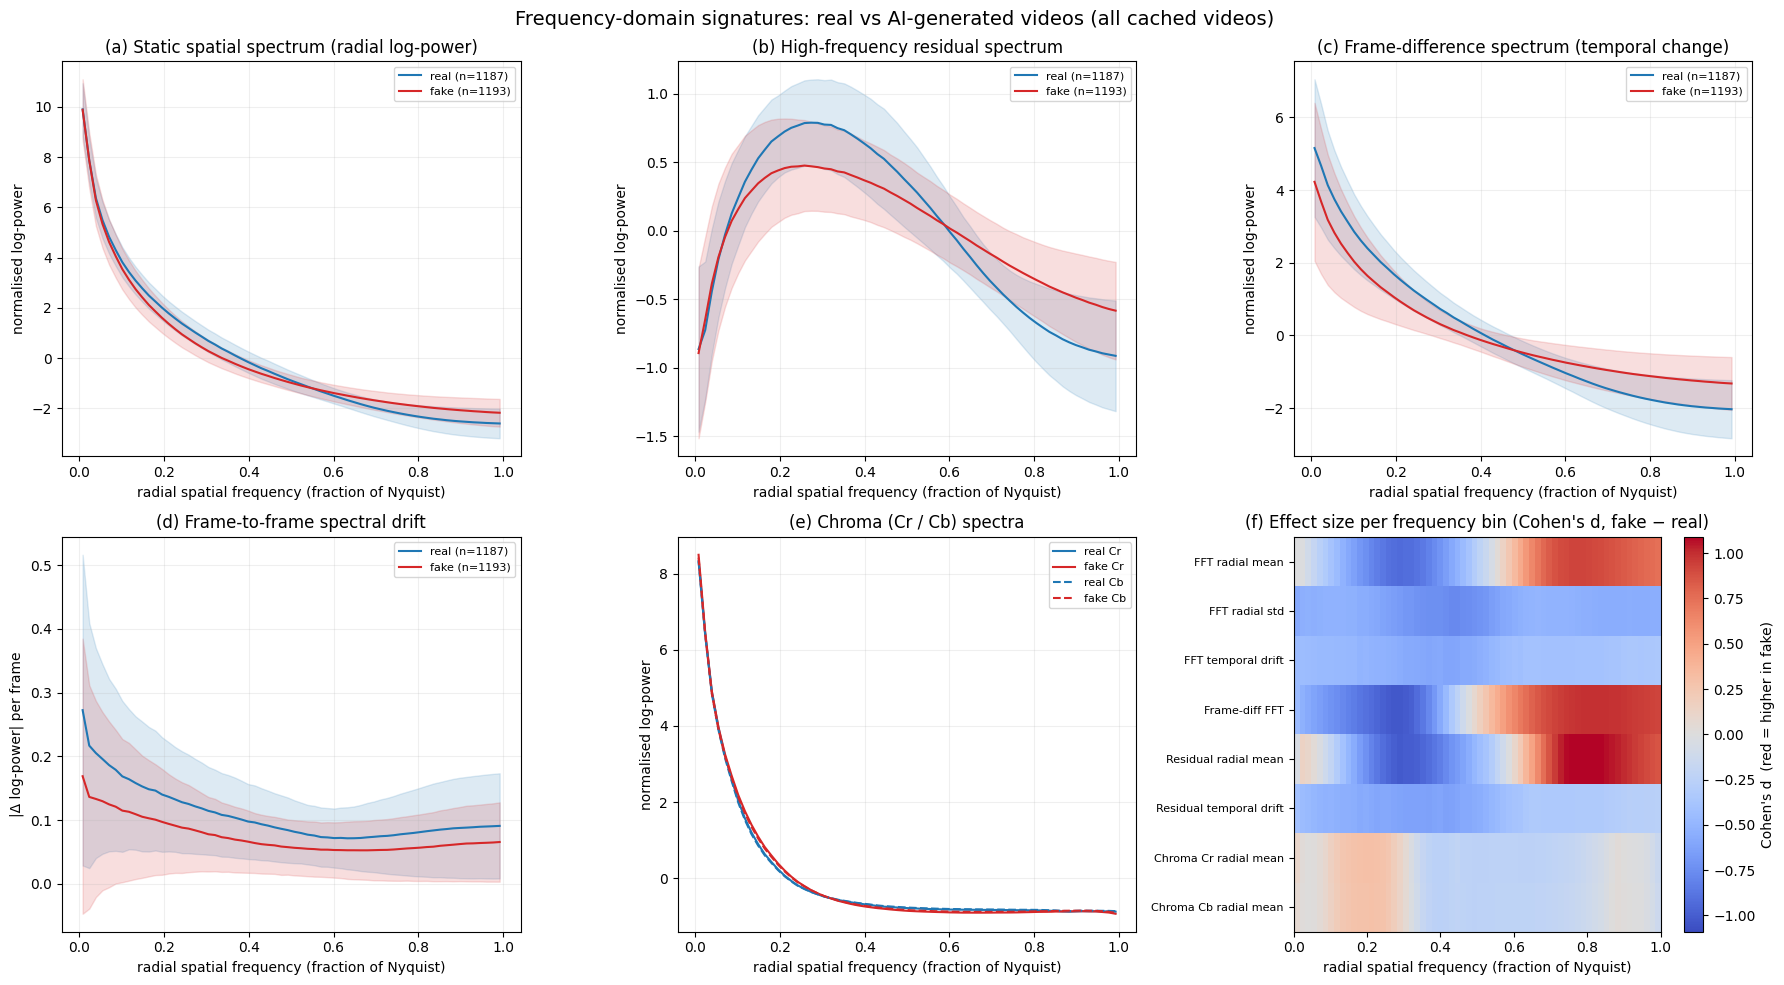

Saved: /content/drive/MyDrive/Data_1/results_v4/interpretability_v4_top6/fig1_class_frequency_signatures.png


PosixPath('/content/drive/MyDrive/Data_1/results_v4/interpretability_v4_top6/fig1_class_frequency_signatures.png')

In [16]:
# ============================================================
# 16B. Class-average frequency-domain signatures (from cached features)
# ============================================================
X_real, X_fake = X[y == 0], X[y == 1]

def plot_profile(ax, block, title, ylabel='normalised log-power'):
    idx = block_bin_indices(block)
    for lab, Xc in [(0, X_real), (1, X_fake)]:
        m, s = Xc[:, idx].mean(axis=0), Xc[:, idx].std(axis=0)
        ax.plot(FREQ_AXIS, m, color=CLASS_COLORS[lab], label=f'{CLASS_NAMES[lab]} (n={len(Xc)})')
        ax.fill_between(FREQ_AXIS, m - s, m + s, color=CLASS_COLORS[lab], alpha=0.15)
    ax.set(title=title, xlabel='radial spatial frequency (fraction of Nyquist)', ylabel=ylabel)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
plot_profile(axes[0, 0], 'FFT radial mean', '(a) Static spatial spectrum (radial log-power)')
plot_profile(axes[0, 1], 'Residual radial mean', '(b) High-frequency residual spectrum')
plot_profile(axes[0, 2], 'Frame-diff FFT', '(c) Frame-difference spectrum (temporal change)')
plot_profile(axes[1, 0], 'FFT temporal drift', '(d) Frame-to-frame spectral drift', ylabel='|Δ log-power| per frame')

ax = axes[1, 1]
for block, ls in [('Chroma Cr radial mean', '-'), ('Chroma Cb radial mean', '--')]:
    idx = block_bin_indices(block)
    for lab, Xc in [(0, X_real), (1, X_fake)]:
        ax.plot(FREQ_AXIS, Xc[:, idx].mean(axis=0), ls, color=CLASS_COLORS[lab],
                label=f"{CLASS_NAMES[lab]} {block.split()[1]}")
ax.set(title='(e) Chroma (Cr / Cb) spectra', xlabel='radial spatial frequency (fraction of Nyquist)',
       ylabel='normalised log-power')
ax.grid(alpha=0.2)
ax.legend(fontsize=8)

# (f) per-bin effect size heat-map
heat_blocks = ['FFT radial mean', 'FFT radial std', 'FFT temporal drift', 'Frame-diff FFT',
               'Residual radial mean', 'Residual temporal drift', 'Chroma Cr radial mean', 'Chroma Cb radial mean']
D = np.stack([cohens_d(X_real[:, block_bin_indices(b)], X_fake[:, block_bin_indices(b)]) for b in heat_blocks])
lim = np.nanpercentile(np.abs(D), 99)
im = axes[1, 2].imshow(D, aspect='auto', cmap='coolwarm', vmin=-lim, vmax=lim,
                       extent=[0, 1, len(heat_blocks) - 0.5, -0.5])
axes[1, 2].set_yticks(range(len(heat_blocks)))
axes[1, 2].set_yticklabels(heat_blocks, fontsize=8)
axes[1, 2].set(title="(f) Effect size per frequency bin (Cohen's d, fake − real)",
               xlabel='radial spatial frequency (fraction of Nyquist)')
fig.colorbar(im, ax=axes[1, 2], label="Cohen's d  (red = higher in fake)")
fig.suptitle('Frequency-domain signatures: real vs AI-generated videos (all cached videos)', fontsize=14)
fig.tight_layout()
save_and_show(fig, 'fig1_class_frequency_signatures.png')

IG completeness check (corr of Σattr vs margin change): 1.0000  (≈1 means faithful)


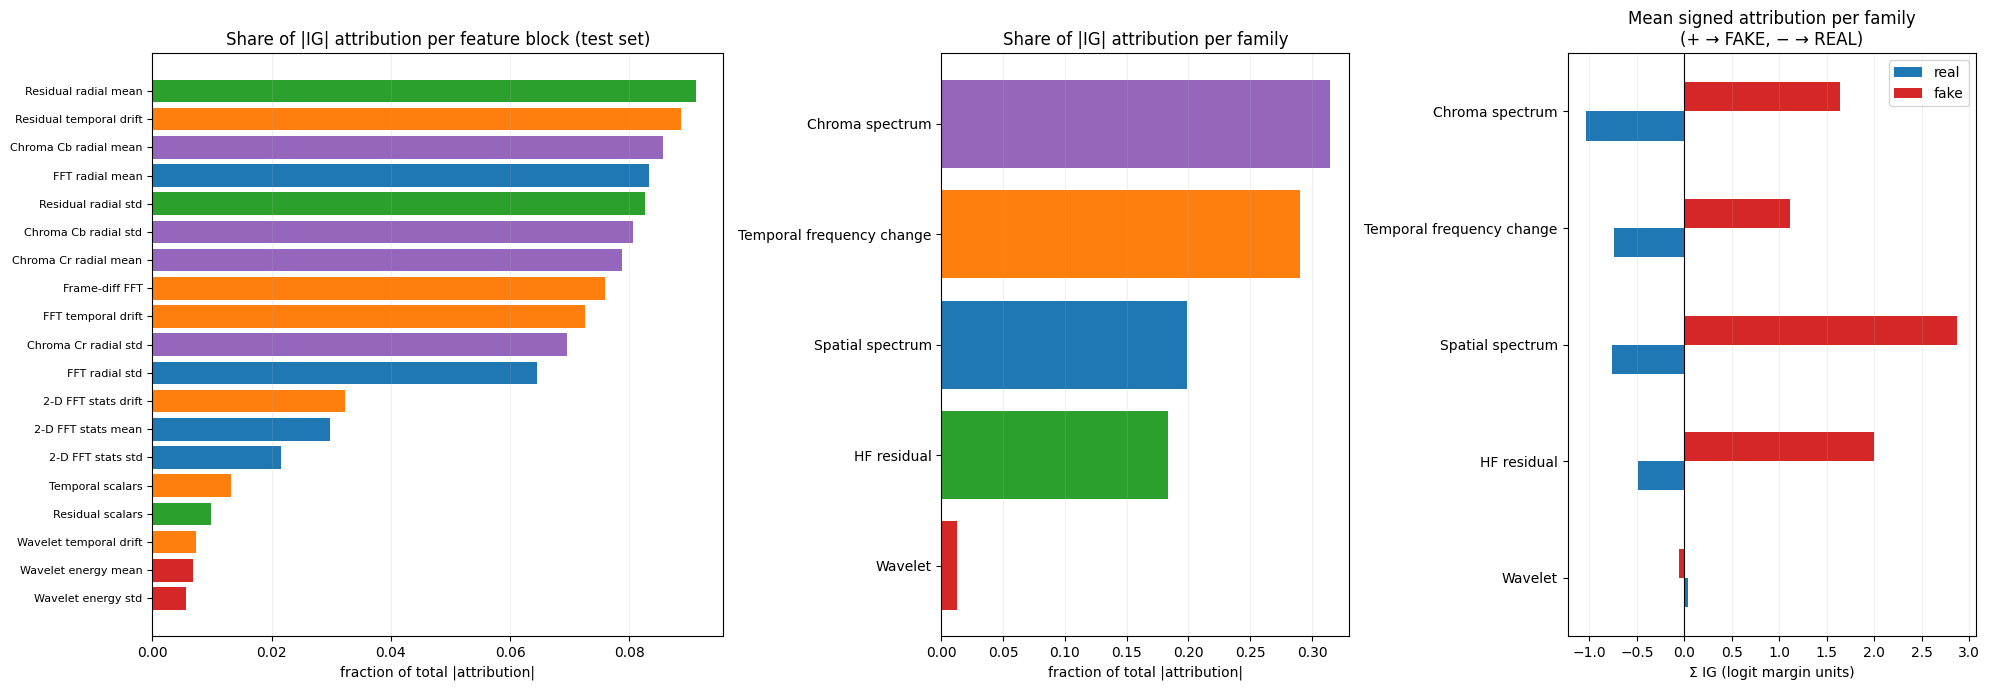

Saved: /content/drive/MyDrive/Data_1/results_v4/interpretability_v4_top6/fig2_attribution_by_block_and_family.png


PosixPath('/content/drive/MyDrive/Data_1/results_v4/interpretability_v4_top6/fig2_attribution_by_block_and_family.png')

In [17]:
# ============================================================
# 16C. What does the classifier use? Integrated Gradients + permutation importance
#      (gradients are taken w.r.t. the inputs only; model weights are unchanged)
# ============================================================
model.eval()

def integrated_gradients(net, x, steps=IG_STEPS, chunk=64):
    # IG of the logit margin (fake − real) w.r.t. normalised inputs; baseline = 0 (= training mean).
    out = torch.zeros_like(x)
    alphas = (torch.arange(steps, dtype=torch.float32) + 0.5) / steps
    for s in range(0, len(x), chunk):
        xb = x[s:s + chunk]
        grad_sum = torch.zeros_like(xb)
        for a in alphas:
            xi = (a * xb).clone().requires_grad_(True)
            logits = net(xi)
            margin = (logits[:, 1] - logits[:, 0]).sum()
            grad_sum += torch.autograd.grad(margin, xi)[0]
        out[s:s + chunk] = xb * grad_sum / steps
    return out

x_test_t = torch.from_numpy(Xn[test_idx]).float().to(device)
IG_TEST = integrated_gradients(model, x_test_t).detach().cpu().numpy()

with torch.no_grad():
    logits_test = model(x_test_t)
    logits_zero = model(torch.zeros(1, X.shape[1], device=device))   # baseline input
margin_test = (logits_test[:, 1] - logits_test[:, 0]).cpu().numpy()
margin_zero = (logits_zero[:, 1] - logits_zero[:, 0]).item()
completeness = np.corrcoef(IG_TEST.sum(axis=1), margin_test - margin_zero)[0, 1]
print(f"IG completeness check (corr of Σattr vs margin change): {completeness:.4f}  (≈1 means faithful)")

# ---------- fig2: importance per block & family ----------
abs_ig = np.abs(IG_TEST)
block_imp = pd.Series({b: abs_ig[:, block_indices(b)].sum(axis=1).mean() for b in BLOCKS})
block_imp = block_imp / block_imp.sum()
fam_imp = block_imp.groupby(BLOCK_TO_FAMILY).sum().sort_values()

signed_by_class = pd.DataFrame({
    CLASS_NAMES[c]: {f: IG_TEST[y_test == c][:, FEATURE_INFO.index[FEATURE_INFO.family == f]].sum(axis=1).mean()
                     for f in FAMILIES} for c in (0, 1)})

fig, axes = plt.subplots(1, 3, figsize=(20, 7), gridspec_kw={'width_ratios': [1.4, 1, 1]})
bs = block_imp.sort_values()
axes[0].barh(bs.index, bs.values, color=[FAMILY_COLORS[BLOCK_TO_FAMILY[b]] for b in bs.index])
axes[0].set(title='Share of |IG| attribution per feature block (test set)', xlabel='fraction of total |attribution|')
axes[0].tick_params(axis='y', labelsize=8)
axes[1].barh(fam_imp.index, fam_imp.values, color=[FAMILY_COLORS[f] for f in fam_imp.index])
axes[1].set(title='Share of |IG| attribution per family', xlabel='fraction of total |attribution|')
signed_by_class.loc[fam_imp.index].plot.barh(ax=axes[2], color=[CLASS_COLORS[0], CLASS_COLORS[1]])
axes[2].axvline(0, color='k', lw=0.8)
axes[2].set(title='Mean signed attribution per family\n(+ → FAKE, − → REAL)', xlabel='Σ IG (logit margin units)')
for a in axes:
    a.grid(alpha=0.2, axis='x')
fig.tight_layout()
save_and_show(fig, 'fig2_attribution_by_block_and_family.png')



Reading real test videos:   0%|          | 0/12 [00:00<?, ?it/s]

Reading fake test videos:   0%|          | 0/12 [00:00<?, ?it/s]

{'real': 12, 'fake': 12} videos analysed


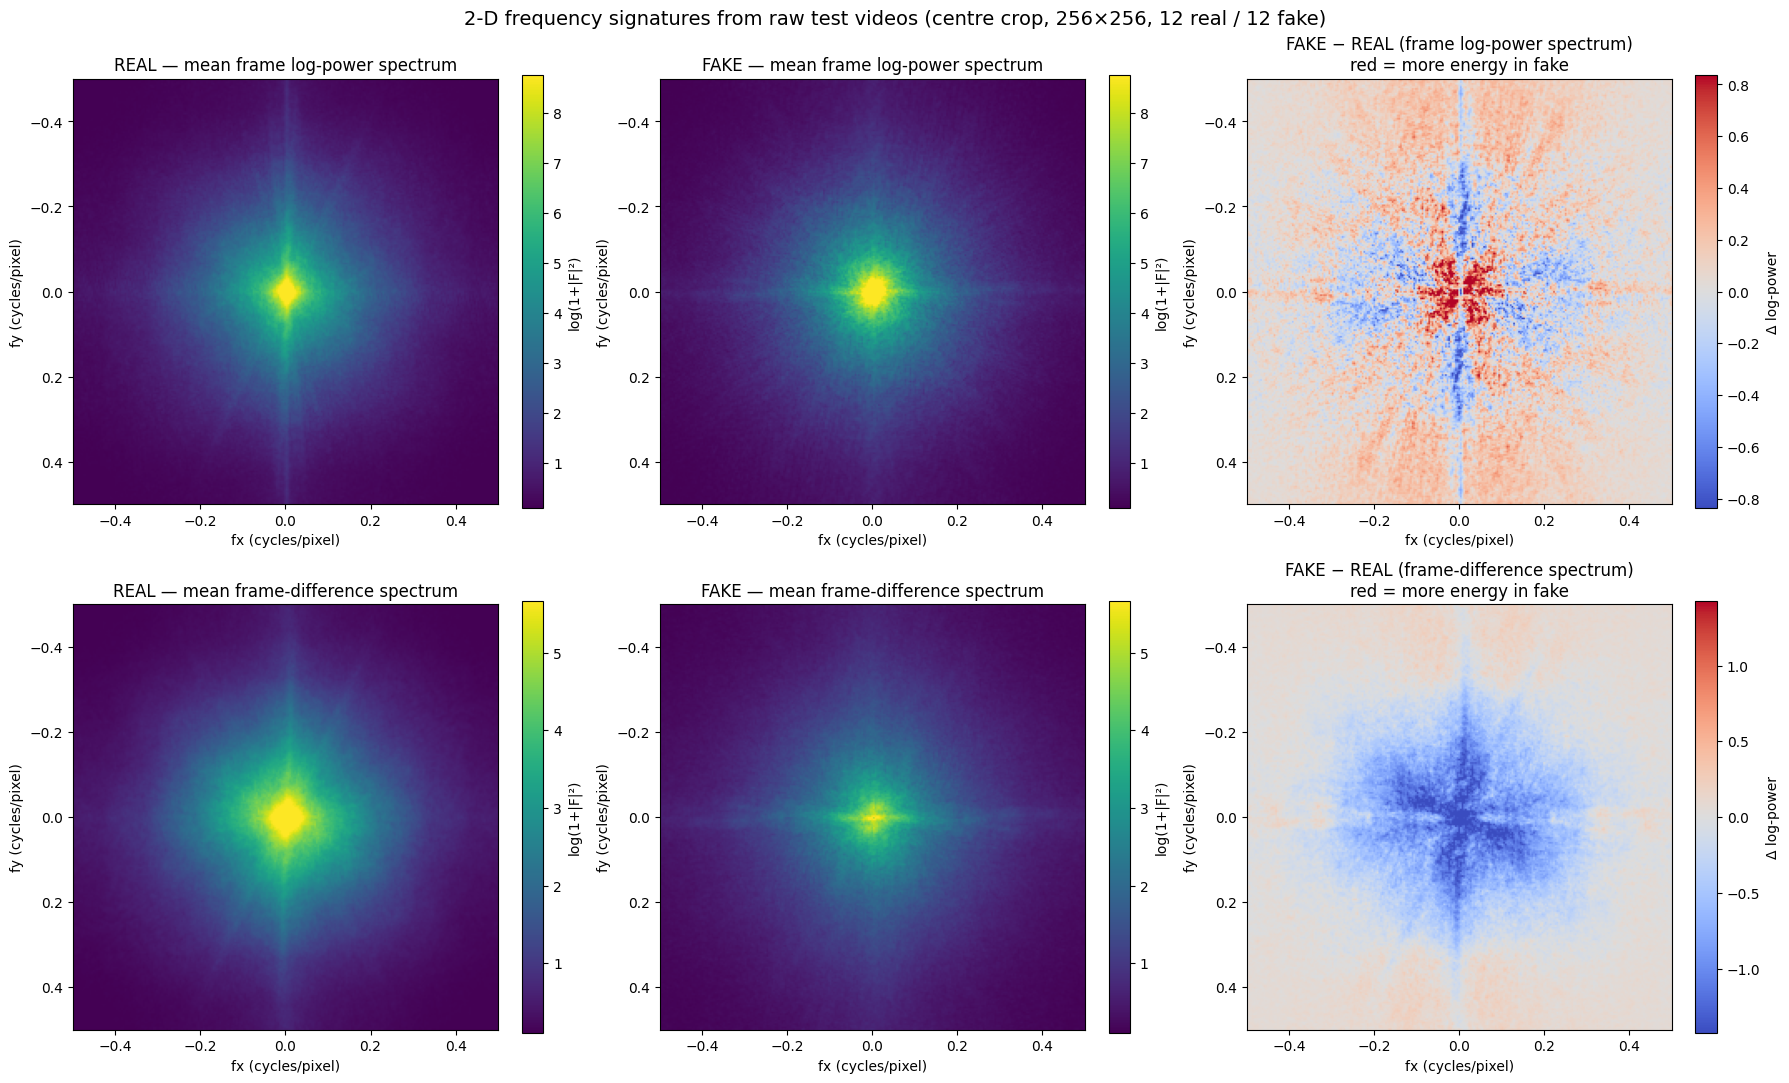

Saved: /content/drive/MyDrive/Data_1/results_v4/interpretability_v4_top6/fig5_2d_frequency_spectra.png


In [18]:
# ============================================================
# 16D. Raw-video 2-D frequency spectra (re-reads a few test videos with the SAME
#      sampling/crop/FFT helpers used by the feature extractor)
# ============================================================
def video_frequency_trace(path):
    # Mean 2-D log-power spectrum of the frames and of the frame differences (centre crop).
    segments, _ = read_temporal_segments(path)
    spec_sum, diff_sum, n_spec, n_diff = 0.0, 0.0, 0, 0
    for seg in segments:
        crop = get_crops(seg)[0]                      # centre crop (crop #0 of the extractor)
        gray = np.stack([cv2.cvtColor(np.ascontiguousarray(f), cv2.COLOR_BGR2GRAY) for f in crop]).astype(np.float32) / 255.0
        spec = fft_log_power(gray)
        spec_sum, n_spec = spec_sum + spec.sum(axis=0), n_spec + len(spec)
        if len(gray) > 1:
            dspec = fft_log_power(gray[1:] - gray[:-1])
            diff_sum, n_diff = diff_sum + dspec.sum(axis=0), n_diff + len(dspec)
    return {'spec2d': spec_sum / max(n_spec, 1),
            'diff2d': diff_sum / n_diff if n_diff else None}


# ----- sample test videos per class -----
viz_traces = {0: [], 1: []}
for c in (0, 1):
    pos = np.where(y_test == c)[0]
    pick = viz_rng.choice(pos, size=min(N_VIZ_VIDEOS_PER_CLASS, len(pos)), replace=False)
    for p in tqdm(pick, desc=f'Reading {CLASS_NAMES[c]} test videos'):
        try:
            viz_traces[c].append(video_frequency_trace(paths[test_idx[p]]))
        except Exception as e:
            print("skip", Path(paths[test_idx[p]]).name, "|", e)
print({CLASS_NAMES[c]: len(v) for c, v in viz_traces.items()}, "videos analysed")

if min(len(v) for v in viz_traces.values()) == 0:
    print("Not enough readable videos for the 2-D spectrum figure (see the 'skip' messages above).")
else:
    ext = [-0.5, 0.5, 0.5, -0.5]   # cycles / pixel

    def mean_of(c, key):
        arr = [t[key] for t in viz_traces[c] if t[key] is not None]
        return np.mean(arr, axis=0) if arr else None

    # ---------- fig5: 2-D spectra ----------
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    for r, (key, name) in enumerate([('spec2d', 'frame log-power spectrum'), ('diff2d', 'frame-difference spectrum')]):
        mr, mf = mean_of(0, key), mean_of(1, key)
        if mr is None or mf is None:
            for a in axes[r]:
                a.set_axis_off()
            continue
        vmin, vmax = np.percentile(np.r_[mr.ravel(), mf.ravel()], [1, 99.8])
        for a, mm, title in [(axes[r, 0], mr, f'REAL — mean {name}'), (axes[r, 1], mf, f'FAKE — mean {name}')]:
            im = a.imshow(mm, cmap='viridis', vmin=vmin, vmax=vmax, extent=ext)
            a.set(title=title, xlabel='fx (cycles/pixel)', ylabel='fy (cycles/pixel)')
            fig.colorbar(im, ax=a, fraction=0.046, label='log(1+|F|²)')
        diff = mf - mr
        lim = np.percentile(np.abs(diff), 99.5) + 1e-12
        im = axes[r, 2].imshow(diff, cmap='coolwarm', vmin=-lim, vmax=lim, extent=ext)
        axes[r, 2].set(title=f'FAKE − REAL ({name})\nred = more energy in fake', xlabel='fx (cycles/pixel)',
                       ylabel='fy (cycles/pixel)')
        fig.colorbar(im, ax=axes[r, 2], fraction=0.046, label='Δ log-power')
    fig.suptitle(f'2-D frequency signatures from raw test videos (centre crop, {CROP_SIZE}×{CROP_SIZE}, '
                 f'{len(viz_traces[0])} real / {len(viz_traces[1])} fake)', fontsize=14)
    fig.tight_layout()
    save_and_show(fig, 'fig5_2d_frequency_spectra.png')

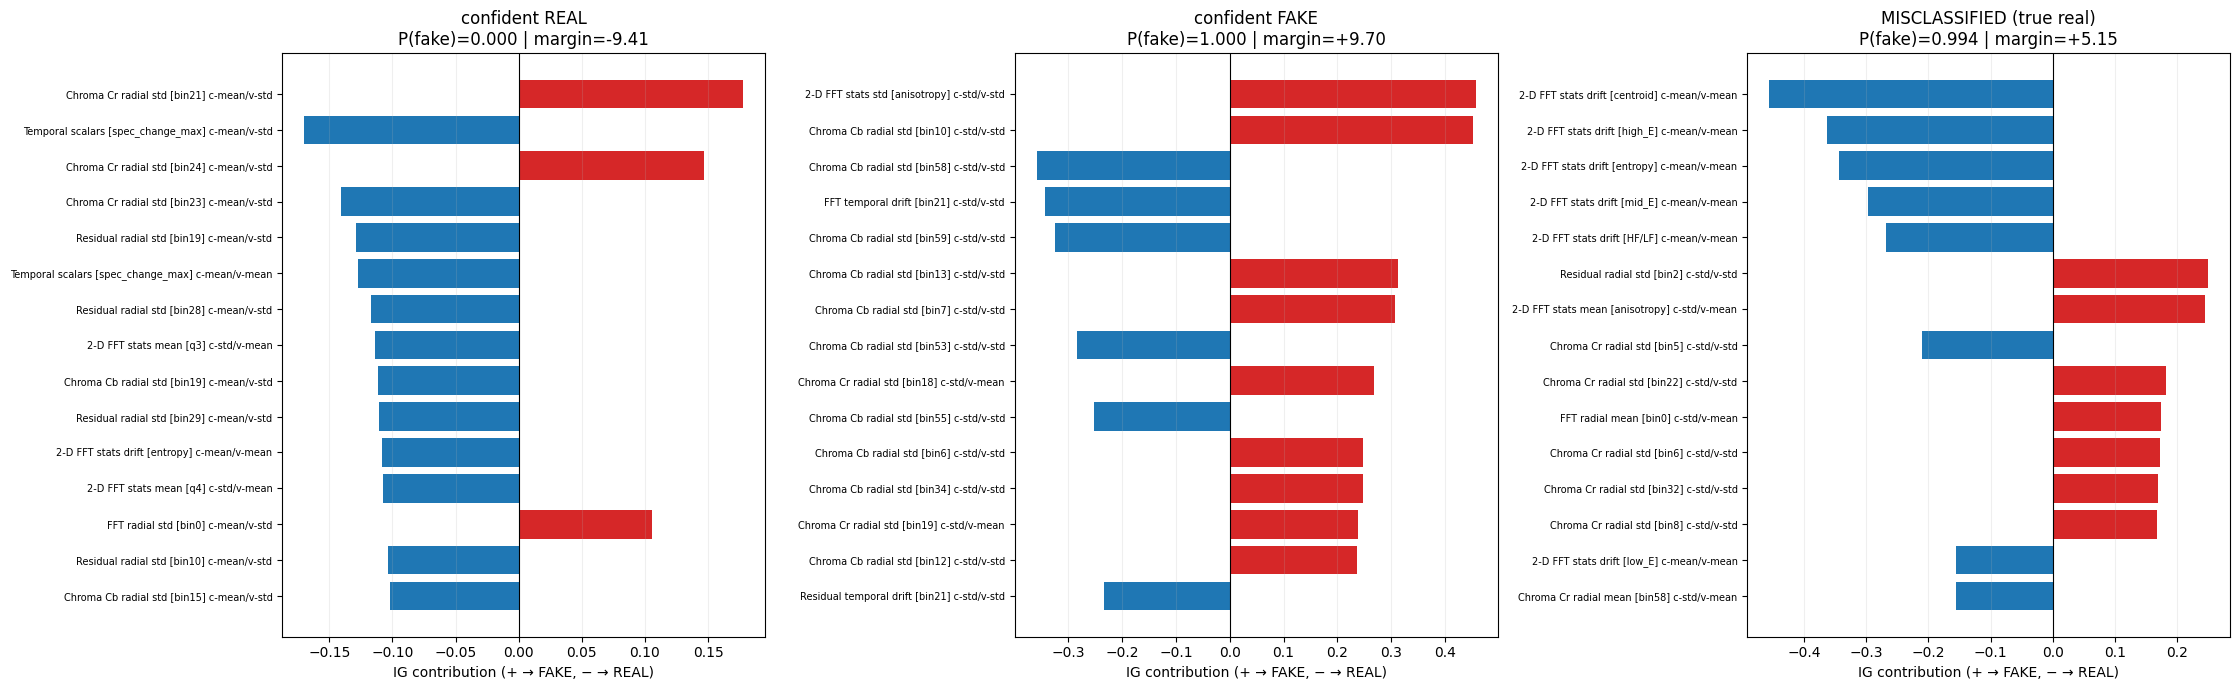

Saved: /content/drive/MyDrive/Data_1/results_v4/interpretability_v4_top6/fig6_per_video_top_feature_contributions.png
Saved: /content/drive/MyDrive/Data_1/results_v4/interpretability_v4_top6/test_per_video_block_attributions.csv


In [19]:
# ============================================================
# 16E. Per-video explanations: confident REAL, confident FAKE and misclassified examples
#      (uses the saved IG values only — no raw video is re-read)
# ============================================================
example_pos = {}
real_pos, fake_pos = np.where(y_test == 0)[0], np.where(y_test == 1)[0]
example_pos['confident REAL'] = real_pos[np.argmin(p_test[real_pos])]
example_pos['confident FAKE'] = fake_pos[np.argmax(p_test[fake_pos])]
wrong_pos = np.where(pred_test != y_test)[0]
if len(wrong_pos):
    worst = wrong_pos[np.argmax(np.abs(p_test[wrong_pos] - BEST_THRESHOLD))]
    example_pos[f'MISCLASSIFIED (true {CLASS_NAMES[y_test[worst]]})'] = worst

# ---------- fig6: top feature contributions ----------
TOP_K = 15
fig, axes = plt.subplots(1, len(example_pos), figsize=(7.5 * len(example_pos), 7), squeeze=False)
for a, (name, pos) in zip(axes[0], example_pos.items()):
    contrib = IG_TEST[pos]
    top = np.argsort(np.abs(contrib))[::-1][:TOP_K][::-1]
    a.barh(FEATURE_INFO.loc[top, 'label'], contrib[top],
           color=['tab:red' if v > 0 else 'tab:blue' for v in contrib[top]])
    a.axvline(0, color='k', lw=0.8)
    a.set(title=f"{name}\nP(fake)={p_test[pos]:.3f} | margin={margin_test[pos]:+.2f}",
          xlabel='IG contribution (+ → FAKE, − → REAL)')
    a.tick_params(axis='y', labelsize=7)
    a.grid(alpha=0.2, axis='x')
fig.tight_layout()
save_and_show(fig, 'fig6_per_video_top_feature_contributions.png')

# Save a table of per-block contributions for every test video (for the report)
per_video_block = pd.DataFrame({b: IG_TEST[:, block_indices(b)].sum(axis=1) for b in BLOCKS})
per_video_block.insert(0, 'path', paths[test_idx])
per_video_block.insert(1, 'true_label', [CLASS_NAMES[c] for c in y_test])
per_video_block.insert(2, 'p_fake', p_test)
per_video_block.to_csv(INTERP_DIR / 'test_per_video_block_attributions.csv', index=False)
print("Saved:", INTERP_DIR / 'test_per_video_block_attributions.csv')

# Part E — External testing

## 17. Independent external test folders
Each folder in `EXTERNAL_SETS` (`Data_1/Test`, `Data_1/Test_compress`) has `Real/` and `Fake/` sub-folders (case-insensitive, nested sub-folders allowed) and its own feature cache. With `REBUILD_EXTERNAL_FEATURES = False` the cached features are loaded directly. The saved checkpoint (training-set normalisation + validation threshold) is used; these videos are never used for training or threshold selection.


######## Test ########
Loaded cached features: /content/drive/MyDrive/Data_1/feature_cache_v4/external_test_features_v1.npz
External folder: Test  (n = 201, threshold = 0.50)
accuracy  : 0.8706
precision : 0.9149
recall    : 0.8269
f1        : 0.8687
roc_auc   : 0.9443

              precision    recall  f1-score   support

        real     0.8318    0.9175    0.8725        97
        fake     0.9149    0.8269    0.8687       104

    accuracy                         0.8706       201
   macro avg     0.8733    0.8722    0.8706       201
weighted avg     0.8748    0.8706    0.8706       201



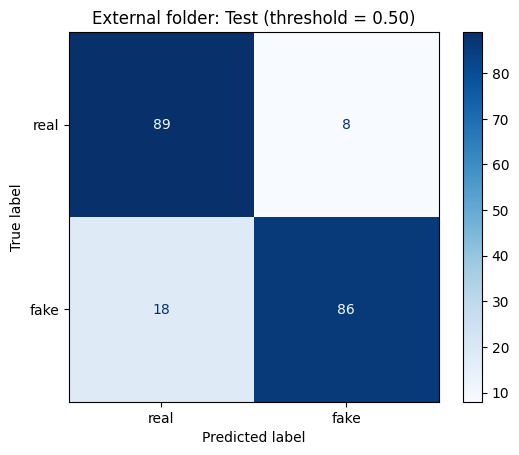

Saved: /content/drive/MyDrive/Data_1/results_v4/external_folder_test_confusion_matrix.png
Saved: /content/drive/MyDrive/Data_1/results_v4/external_folder_test_predictions.csv

######## Test_compress ########
Loaded cached features: /content/drive/MyDrive/Data_1/feature_cache_v4/external_test_compress_features_v4.npz
External folder: Test_compress  (n = 107, threshold = 0.50)
accuracy  : 0.7664
precision : 0.8125
recall    : 0.7091
f1        : 0.7573
roc_auc   : 0.8997

              precision    recall  f1-score   support

        real     0.7288    0.8269    0.7748        52
        fake     0.8125    0.7091    0.7573        55

    accuracy                         0.7664       107
   macro avg     0.7707    0.7680    0.7660       107
weighted avg     0.7718    0.7664    0.7658       107



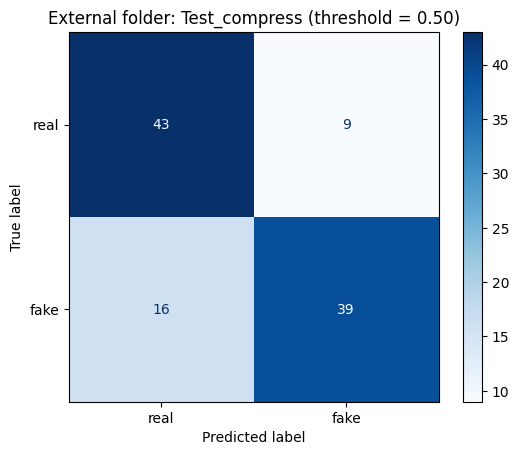

Saved: /content/drive/MyDrive/Data_1/results_v4/external_folder_compress_test_confusion_matrix.png
Saved: /content/drive/MyDrive/Data_1/results_v4/external_folder_compress_test_predictions.csv

Summary (threshold = 0.50):


,accuracy,precision,recall,f1,roc_auc
Internal test,0.9549,0.9655,0.9438,0.9545,0.9911
Test,0.8706,0.9149,0.8269,0.8687,0.9443
Test_compress,0.7664,0.8125,0.7091,0.7573,0.8997


In [20]:
# ============================================================
# 17. External test folders — evaluation with the saved checkpoint
# ============================================================
def load_detector(ckpt_path=CHECKPOINT):
    """Saved MLP + training-set normalisation + validation-selected threshold."""
    ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    if ckpt.get('feature_version', FEATURE_VERSION) != FEATURE_VERSION:
        raise RuntimeError(f"Feature-version mismatch: checkpoint={ckpt['feature_version']}, current={FEATURE_VERSION}")
    net = FreqMLP(ckpt['in_dim'], hidden=tuple(ckpt.get('hidden', HIDDEN)), dropout=float(ckpt.get('dropout', DROPOUT)))
    net.load_state_dict(ckpt['state_dict'])
    net.eval()
    std_ = ckpt['std'].numpy().astype(np.float32)
    std_[std_ < 1e-6] = 1.0
    return net, ckpt['mean'].numpy().astype(np.float32), std_, float(ckpt['threshold'])


det_model, det_mean, det_std, det_threshold = load_detector()

all_results = {'Internal test': {k: v for k, v in test_metrics.items() if k != 'confusion_matrix'}}
for name, cfg in EXTERNAL_SETS.items():
    print(f"\n######## {name} ########")
    X_ext, y_ext, paths_ext = load_or_extract_features(cfg['cache'], cfg['dir'], REBUILD_EXTERNAL_FEATURES,
                                                       f'{name} features')
    if X_ext.shape[1] != det_mean.shape[0]:
        raise ValueError(f"Feature dimension {X_ext.shape[1]} != model input {det_mean.shape[0]}")

    p_ext = predict_proba(det_model, (X_ext - det_mean) / det_std)
    pred_ext = (p_ext >= det_threshold).astype(int)
    pd.DataFrame({'video_path': paths_ext, 'true_class': np.where(y_ext == 1, 'fake', 'real'),
                  'p_real': 1 - p_ext, 'p_fake': p_ext,
                  'predicted_class': np.where(pred_ext == 1, 'fake', 'real'), 'correct': pred_ext == y_ext}
                 ).to_csv(RESULT_DIR / f"{cfg['tag']}_predictions.csv", index=False)

    m = report(f'External folder: {name}', y_ext, p_ext, det_threshold,
               RESULT_DIR / f"{cfg['tag']}_confusion_matrix.png")
    all_results[name] = {k: v for k, v in m.items() if k != 'confusion_matrix'}
    print('Saved:', RESULT_DIR / f"{cfg['tag']}_predictions.csv")

summary_df = pd.DataFrame(all_results).T
summary_df.to_csv(RESULT_DIR / 'evaluation_summary_v4.csv')
print('\nSummary (threshold = %.2f):' % det_threshold)
display(summary_df.style.format('{:.4f}'))

## 18. Classify a single uploaded video
Upload a video from your computer; it is processed with the same feature extractor and the saved checkpoint, and the temporary copy is deleted afterwards. It is not added to the dataset. Sections 2–6 and 9 must have been run first (feature functions + model class).

In [21]:
# ============================================================
# 18. Single-video prediction (upload from your computer)
# ============================================================
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise RuntimeError('No video was uploaded.')
video_path = Path('/content') / next(iter(uploaded))

det_model, det_mean, det_std, det_threshold = load_detector()
feature = extract_video_features_v4(video_path)
prob_fake = float(predict_proba(det_model, ((feature - det_mean) / det_std)[None, :])[0])
video_path.unlink(missing_ok=True)

print('=' * 50)
print(f"Video            : {video_path.name}")
print(f"Prediction       : {'AI-GENERATED' if prob_fake >= det_threshold else 'REAL'}")
print(f"P(REAL)          : {1 - prob_fake:.4f}")
print(f"P(AI-GENERATED)  : {prob_fake:.4f}")
print(f"Threshold        : {det_threshold:.2f}")
print('=' * 50)

KeyboardInterrupt: 